In [26]:
import numpy as np #NumPy for numerical calculations and random data generation,
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats #SciPy for probability distributions
import pandas as pd

In [27]:
np.random.seed(42)

In [28]:
print("=" * 60)
print("NORMAL DISTRIBUTION  N(μ, σ²)")
print("=" * 60)

NORMAL DISTRIBUTION  N(μ, σ²)


In [29]:
params = [(0, 1), (2, 1), (0, 2), (-2, 0.5)]
x = np.linspace(-8, 8, 400)

In [30]:
print("\nNormal Distribution Properties:")
for mu, sigma in params:
    dist = stats.norm(mu, sigma)
    print(f"\n  N(μ={mu}, σ={sigma}):")
    print(f"  Mean={dist.mean():.2f}, Var={dist.var():.2f},"
          f" Skew={dist.stats('s'):.2f},"
          f" Kurt={dist.stats('k'):.2f}")


Normal Distribution Properties:

  N(μ=0, σ=1):
  Mean=0.00, Var=1.00, Skew=0.00, Kurt=0.00

  N(μ=2, σ=1):
  Mean=2.00, Var=1.00, Skew=0.00, Kurt=0.00

  N(μ=0, σ=2):
  Mean=0.00, Var=4.00, Skew=0.00, Kurt=0.00

  N(μ=-2, σ=0.5):
  Mean=-2.00, Var=0.25, Skew=0.00, Kurt=0.00


In [31]:
std_normal = stats.norm(0, 1)
print("\n68-95-99.7 Rule Verification:")
print(f"  P(-1 < Z < 1)  = {std_normal.cdf(1) - std_normal.cdf(-1):.6f} ≈ 68.27%")
print(f"  P(-2 < Z < 2)  = {std_normal.cdf(2) - std_normal.cdf(-2):.6f} ≈ 95.45%")
print(f"  P(-3 < Z < 3)  = {std_normal.cdf(3) - std_normal.cdf(-3):.6f} ≈ 99.73%")


68-95-99.7 Rule Verification:
  P(-1 < Z < 1)  = 0.682689 ≈ 68.27%
  P(-2 < Z < 2)  = 0.954500 ≈ 95.45%
  P(-3 < Z < 3)  = 0.997300 ≈ 99.73%


In [32]:
print("\nZ-score Examples:")
raw_scores = [60, 70, 80, 90]
mu_exam, sigma_exam = 70, 10
for score in raw_scores:
    z = (score - mu_exam) / sigma_exam
    percentile = std_normal.cdf(z) * 100
    print(f"  Score={score}, Z={z:.2f}, Percentile={percentile:.1f}%")


Z-score Examples:
  Score=60, Z=-1.00, Percentile=15.9%
  Score=70, Z=0.00, Percentile=50.0%
  Score=80, Z=1.00, Percentile=84.1%
  Score=90, Z=2.00, Percentile=97.7%


In [33]:
print("\n  ML Context — Weight Initialization:")
print(f"  Xavier init: W ~ N(0, 2/(n_in + n_out))")
n_in, n_out = 784, 128
xavier_std = np.sqrt(2 / (n_in + n_out))
print(f"  For Dense(784→128): σ = {xavier_std:.6f}")


  ML Context — Weight Initialization:
  Xavier init: W ~ N(0, 2/(n_in + n_out))
  For Dense(784→128): σ = 0.046829


In [34]:
print("\n" + "=" * 60)
print("EXPONENTIAL DISTRIBUTION  Exp(λ)")
print("=" * 60)


EXPONENTIAL DISTRIBUTION  Exp(λ)


In [35]:
lambdas_exp = [0.5, 1.0, 2.0, 3.0]
x_exp = np.linspace(0, 8, 300)

In [36]:

for lam in lambdas_exp:
    dist_e = stats.expon(scale=1/lam)
    print(f"\n  Exp(λ={lam}): Mean={dist_e.mean():.4f},"
          f" Var={dist_e.var():.4f},"
          f" Std={dist_e.std():.4f}")


  Exp(λ=0.5): Mean=2.0000, Var=4.0000, Std=2.0000

  Exp(λ=1.0): Mean=1.0000, Var=1.0000, Std=1.0000

  Exp(λ=2.0): Mean=0.5000, Var=0.2500, Std=0.5000

  Exp(λ=3.0): Mean=0.3333, Var=0.1111, Std=0.3333


In [37]:
lam_main = 1.0
exp_main = stats.expon(scale=1/lam_main)
exp_data = np.random.exponential(1/lam_main, 5000)
print(f"\n  Memoryless Property (λ={lam_main}):")
print(f"  P(X > 2)            = {1 - exp_main.cdf(2):.6f}")
print(f"  P(X > 3 | X > 1)    = {(1 - exp_main.cdf(3)) / (1 - exp_main.cdf(1)):.6f}")
print(f"  Both equal? {abs((1-exp_main.cdf(2)) - (1-exp_main.cdf(3))/(1-exp_main.cdf(1))) < 1e-9}")


  Memoryless Property (λ=1.0):
  P(X > 2)            = 0.135335
  P(X > 3 | X > 1)    = 0.135335
  Both equal? True


NameError: name 'distributions_clt' is not defined

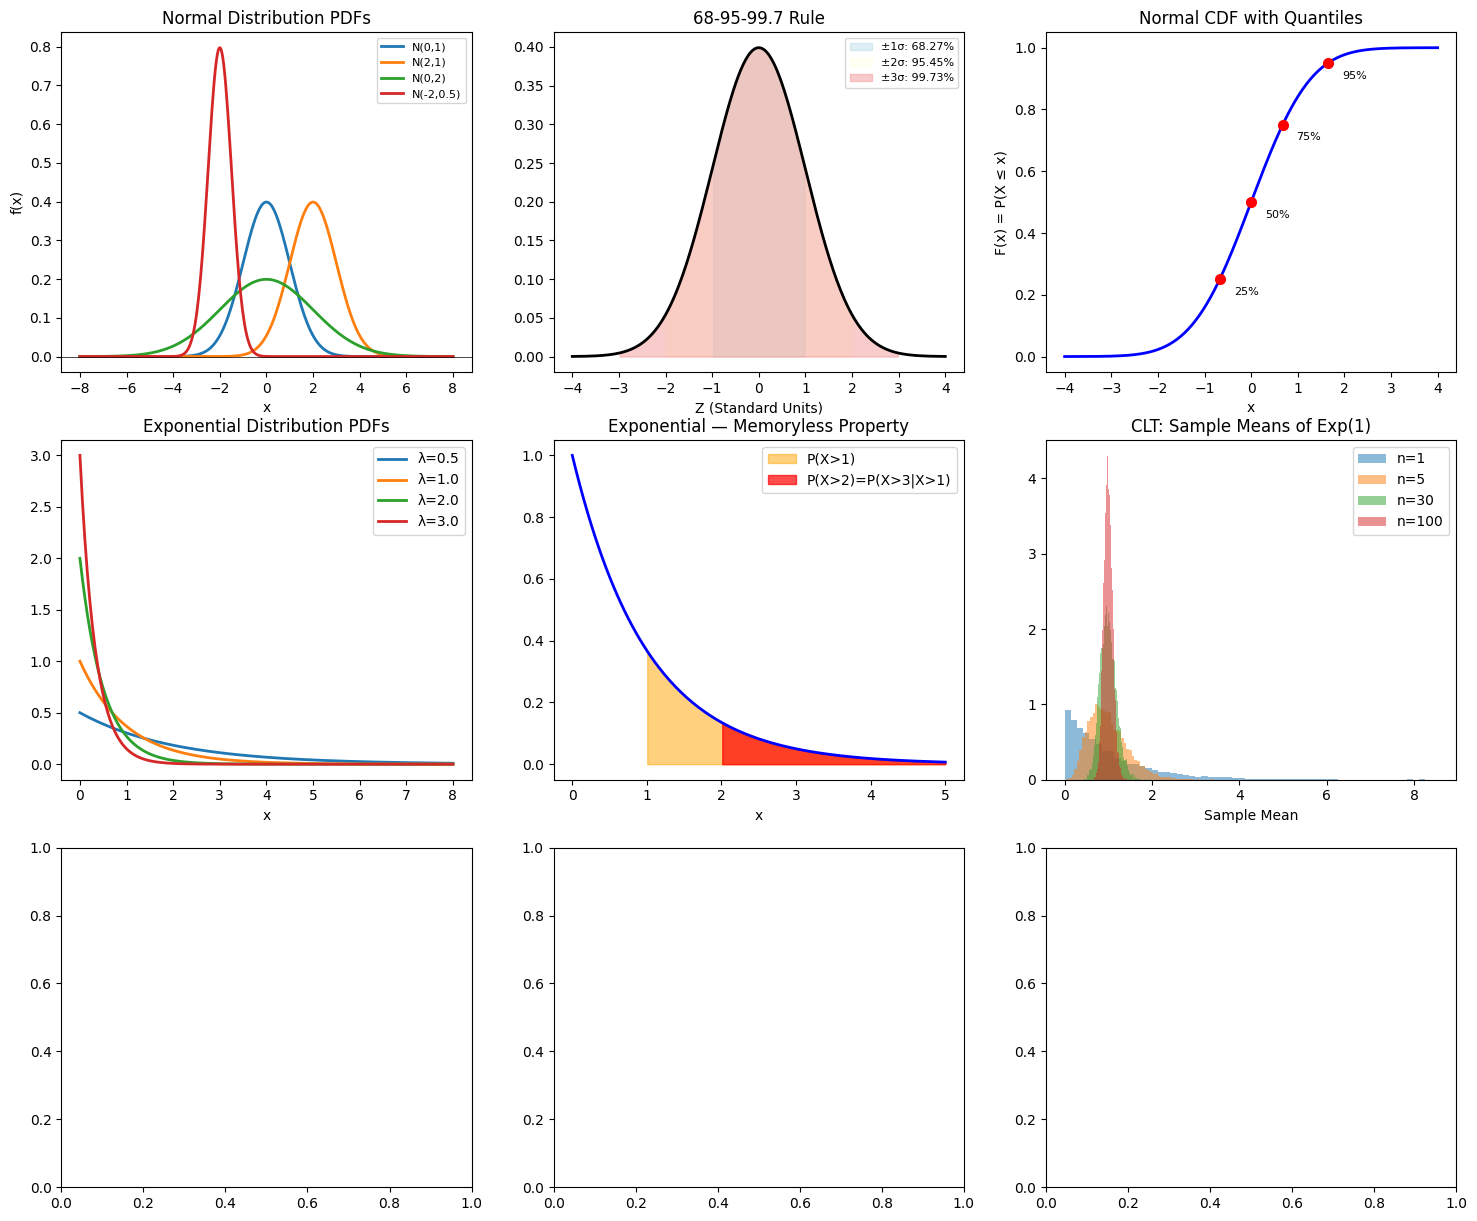

In [46]:
ig, axes = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle('Continuous Distributions — Normal, Exponential & CLT',
             fontsize=16, fontweight='bold')

# 1. Normal PDFs
for mu, sigma in params:
    axes[0, 0].plot(x, stats.norm.pdf(x, mu, sigma),
                    linewidth=2, label=f'N({mu},{sigma})')
axes[0, 0].set_title('Normal Distribution PDFs')
axes[0, 0].set_xlabel('x')
axes[0, 0].set_ylabel('f(x)')
axes[0, 0].legend(fontsize=8)
axes[0, 0].axhline(0, color='black', linewidth=0.5)

# 2. 68-95-99.7 Rule
x_std = np.linspace(-4, 4, 300)
y_std = stats.norm.pdf(x_std)
axes[0, 1].plot(x_std, y_std, 'k-', linewidth=2)
for interval, color, label in [
        (1, 'lightblue', '68.27%'),
        (2, 'lightyellow', '95.45%'),
        (3, 'lightcoral', '99.73%')]:
    axes[0, 1].fill_between(
        x_std, y_std,
        where=(np.abs(x_std) <= interval),
        alpha=0.4, color=color, label=f'±{interval}σ: {label}')
axes[0, 1].set_title('68-95-99.7 Rule')
axes[0, 1].legend(fontsize=8)
axes[0, 1].set_xlabel('Z (Standard Units)')

# 3. Normal CDF
x_cdf = np.linspace(-4, 4, 300)
axes[0, 2].plot(x_cdf, stats.norm.cdf(x_cdf, 0, 1),
                'blue', linewidth=2)
for q_val in [0.25, 0.50, 0.75, 0.95]:
    q_x = stats.norm.ppf(q_val)
    axes[0, 2].plot(q_x, q_val, 'ro', markersize=7)
    axes[0, 2].annotate(f'{q_val:.0%}',
                        xy=(q_x, q_val),
                        xytext=(q_x+0.3, q_val-0.05),
                        fontsize=8)
axes[0, 2].set_title('Normal CDF with Quantiles')
axes[0, 2].set_xlabel('x')
axes[0, 2].set_ylabel('F(x) = P(X ≤ x)')

# 4. Exponential PDFs
for lam in lambdas_exp:
    axes[1, 0].plot(x_exp, stats.expon.pdf(x_exp, scale=1/lam),
                    linewidth=2, label=f'λ={lam}')
axes[1, 0].set_title('Exponential Distribution PDFs')
axes[1, 0].set_xlabel('x')
axes[1, 0].legend()

# 5. Exponential — Memoryless Property
x_mem = np.linspace(0, 5, 200)
axes[1, 1].fill_between(x_mem, exp_main.pdf(x_mem),
                         where=(x_mem >= 1),
                         alpha=0.5, color='orange',
                         label='P(X>1)')
axes[1, 1].fill_between(x_mem, exp_main.pdf(x_mem),
                         where=(x_mem >= 2),
                         alpha=0.7, color='red',
                         label='P(X>2)=P(X>3|X>1)')
axes[1, 1].plot(x_mem, exp_main.pdf(x_mem), 'b-', linewidth=2)
axes[1, 1].set_title('Exponential — Memoryless Property')
axes[1, 1].legend()
axes[1, 1].set_xlabel('x')

# 6. CLT for different sample sizes
clt_data = np.random.exponential(1, (100, 10000))
for i, n in enumerate([1, 5, 30, 100]):
    means = clt_data[:n, :].mean(axis=0)
    axes[1, 2].hist(means, bins=60, density=True, alpha=0.5,
                    label=f'n={n}')
axes[1, 2].set_title('CLT: Sample Means of Exp(1)')
axes[1, 2].set_xlabel('Sample Mean')
axes[1, 2].legend()

# 7-9: CLT for different distributions
for idx, (dist_name, sampler) in enumerate(
        distributions_clt.items()):
    ax = axes[2, idx]
    for n in [1, 5, 30]:
        sample_means = [np.mean(sampler(n)) for _ in range(2000)]
        ax.hist(sample_means, bins=50, density=True,
                alpha=0.5, label=f'n={n}')
    ax.set_title(f'CLT: {dist_name}')
    ax.set_xlabel('Sample Mean')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('P3_continuous_distributions.png', dpi=150,
            bbox_inches='tight')
plt.show()
print("\nProgram 3 Completed Successfully.")

/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


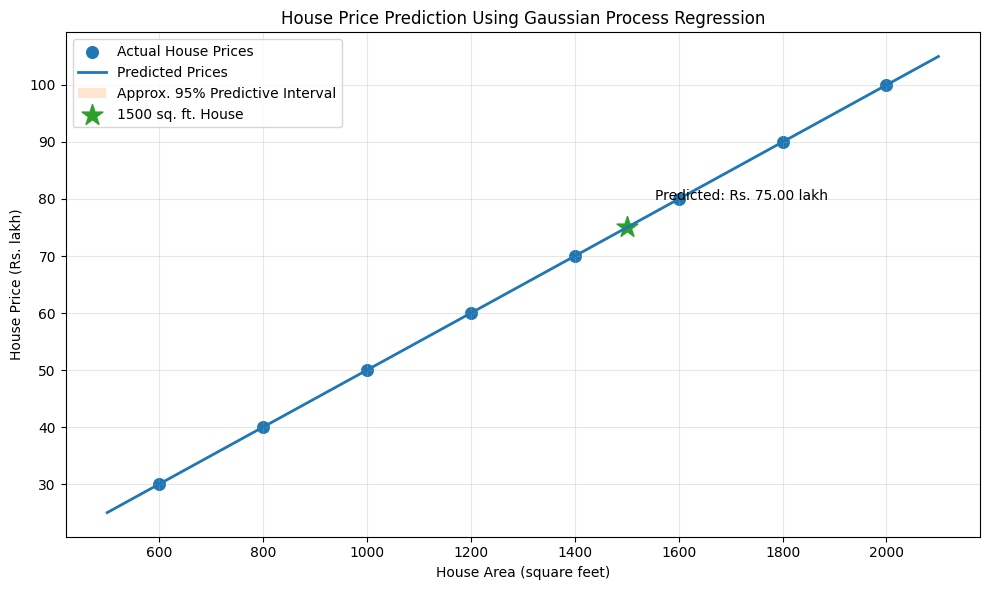

Predicted price for 1500 sq. ft.: 75.0 lakh
Prediction standard deviation: 0.08 lakh


In [49]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, ConstantKernel, WhiteKernel
)

# Sample house dataset
X = np.array([
    [600], [800], [1000], [1200],
    [1400], [1600], [1800], [2000]
])

y = np.array([30, 40, 50, 60, 70, 80, 90, 100])

# Create Gaussian Process Regression model
kernel = (
    ConstantKernel(1.0) * RBF(length_scale=500)
    + WhiteKernel(noise_level=0.1)
)

model = GaussianProcessRegressor(
    kernel=kernel,
    normalize_y=True,
    n_restarts_optimizer=5,
    random_state=42
)

# Train the model
model.fit(X, y)

# Generate points for smooth visualization
X_plot = np.linspace(500, 2100, 200).reshape(-1, 1)

# Predict prices and uncertainty
y_mean, y_std = model.predict(X_plot, return_std=True)

# Create visualization
plt.figure(figsize=(10, 6))

# Actual house prices
plt.scatter(
    X.ravel(), y,
    label="Actual House Prices",
    marker="o",
    s=70
)

# Predicted price curve
plt.plot(
    X_plot.ravel(), y_mean,
    label="Predicted Prices",
    linewidth=2
)

# Gaussian uncertainty interval
plt.fill_between(
    X_plot.ravel(),
    y_mean - 1.96 * y_std,
    y_mean + 1.96 * y_std,
    alpha=0.2,
    label="Approx. 95% Predictive Interval"
)

# Predict a new house price
area = np.array([[1500]])
price, std = model.predict(area, return_std=True)

plt.scatter(
    area.ravel(), price,
    marker="*",
    s=250,
    label="1500 sq. ft. House"
)

plt.annotate(
    f"Predicted: Rs. {price[0]:.2f} lakh",
    (1500, price[0]),
    xytext=(20, 20),
    textcoords="offset points"
)

# Graph formatting
plt.title("House Price Prediction Using Gaussian Process Regression")
plt.xlabel("House Area (square feet)")
plt.ylabel("House Price (Rs. lakh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Predicted price for 1500 sq. ft.:",
      round(price[0], 2), "lakh")
print("Prediction standard deviation:",
      round(std[0], 2), "lakh")


Mean error: 0.00 lakhs
Standard deviation: 4.94 lakhs


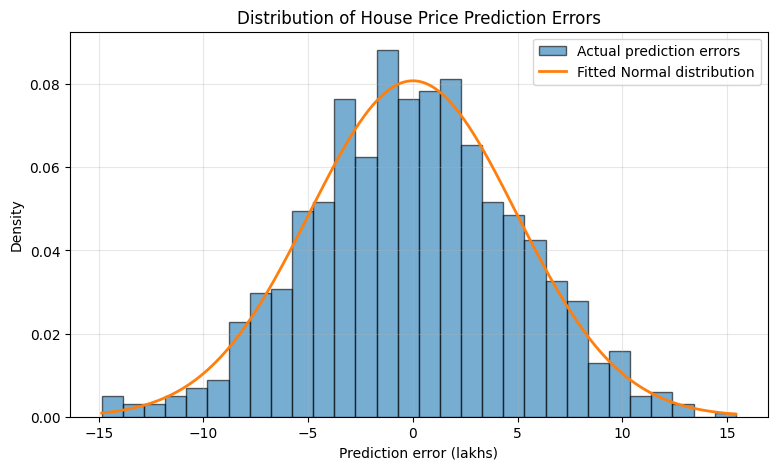

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from scipy.stats import norm

# Make results reproducible
np.random.seed(42)

# Generate synthetic house data
n = 1000
area = np.random.uniform(500, 3000, n)  # Area in sq. ft.
noise = np.random.normal(0, 5, n)       # Noise in lakhs

# House price in lakhs
price = 15 + 0.05 * area + noise

# Train a simple ML model
X = area.reshape(-1, 1)
model = LinearRegression()
model.fit(X, price)

# Predict house prices
predicted = model.predict(X)

# Calculate prediction errors
errors = price - predicted

# Fit a Normal distribution to the errors
mu, sigma = norm.fit(errors)

print(f"Mean error: {mu:.2f} lakhs")
print(f"Standard deviation: {sigma:.2f} lakhs")

# Plot histogram and fitted Normal curve
plt.figure(figsize=(9, 5))

plt.hist(
    errors, bins=30, density=True,
    alpha=0.6, edgecolor="black",
    label="Actual prediction errors"
)

x = np.linspace(errors.min(), errors.max(), 300)
plt.plot(
    x, norm.pdf(x, mu, sigma),
    linewidth=2,
    label="Fitted Normal distribution"
)

plt.title("Distribution of House Price Prediction Errors")
plt.xlabel("Prediction error (lakhs)")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Predicted temperature for day 11: 30.8 °C


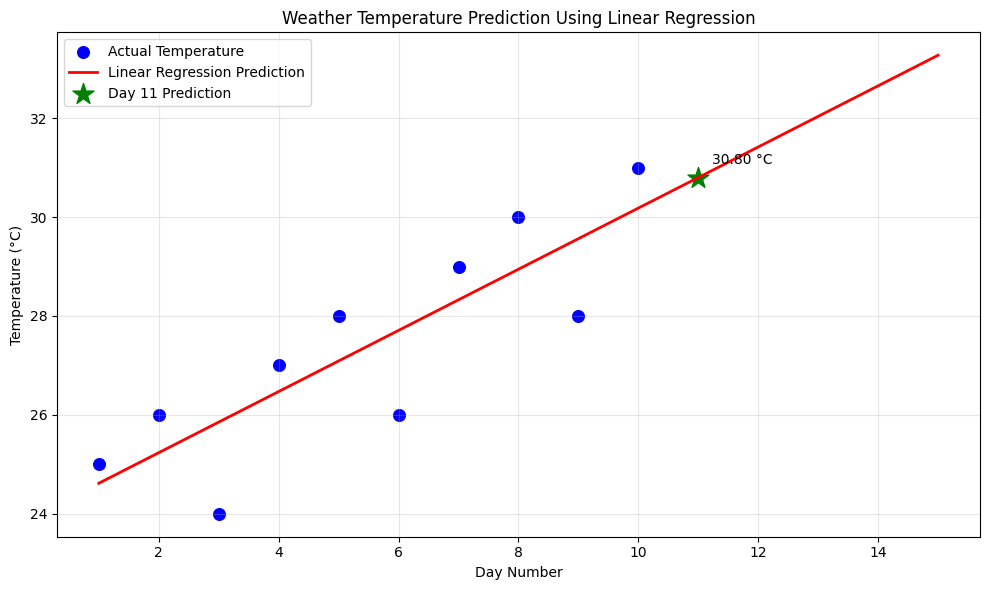

In [52]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Sample weather data
days = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
temperature = np.array([25, 26, 24, 27, 28, 26, 29, 30, 28, 31])

# Train Linear Regression model
model = LinearRegression()
model.fit(days, temperature)

# Predict temperatures
future_days = np.arange(1, 16).reshape(-1, 1)
predicted_temperature = model.predict(future_days)

# Predict temperature for day 11
day11 = np.array([[11]])
prediction = model.predict(day11)

print("Predicted temperature for day 11:",
      round(prediction[0], 2), "°C")

# Visualize results
plt.figure(figsize=(10, 6))

# Actual temperature data
plt.scatter(
    days, temperature,
    color="blue", s=70,
    label="Actual Temperature"
)

# Regression line
plt.plot(
    future_days, predicted_temperature,
    color="red", linewidth=2,
    label="Linear Regression Prediction"
)

# Highlight day 11 prediction
plt.scatter(
    day11, prediction,
    color="green", marker="*",
    s=250, label="Day 11 Prediction"
)

plt.annotate(
    f"{prediction[0]:.2f} °C",
    (11, prediction[0]),
    xytext=(10, 10),
    textcoords="offset points"
)

plt.title("Weather Temperature Prediction Using Linear Regression")
plt.xlabel("Day Number")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Mean Prediction Error: -0.0 lakhs
Standard Deviation of Errors: 1.38 lakhs


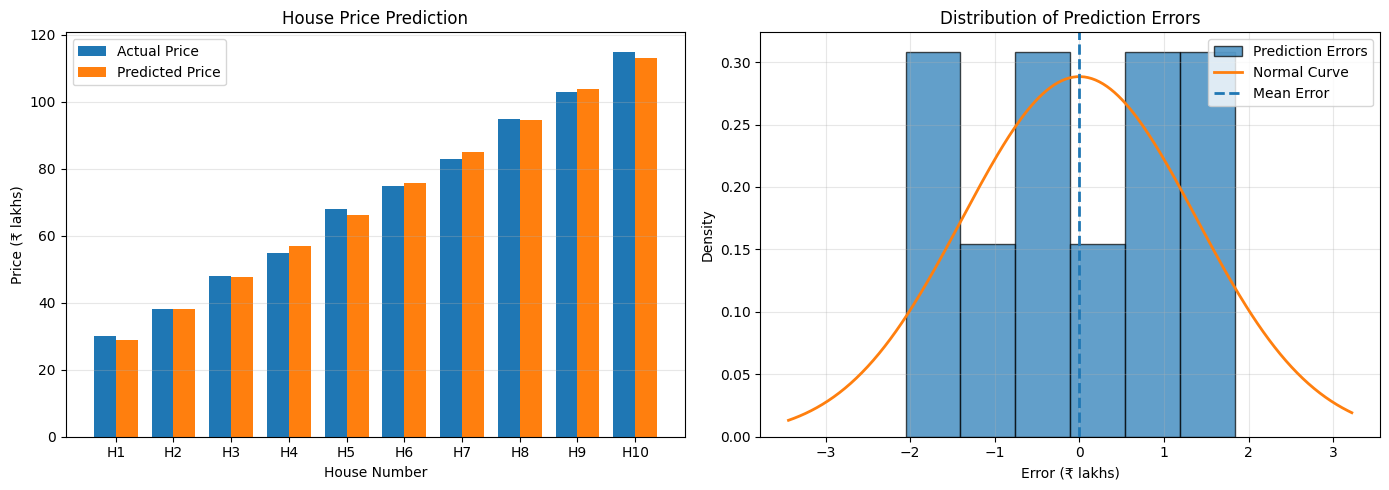

In [57]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Sample real-estate dataset
# House area in square feet
X = np.array([
    600, 800, 1000, 1200, 1400,
    1600, 1800, 2000, 2200, 2400
]).reshape(-1, 1)

# House prices in lakhs of rupees
y = np.array([30, 38, 48, 55, 68, 75, 83, 95, 103, 115])

# Train the ML model
model = LinearRegression()
model.fit(X, y)

# Predict prices for the same houses
predicted = model.predict(X)

# Calculate prediction errors (residuals)
errors = y - predicted

# Calculate mean and standard deviation of errors
mean_error = np.mean(errors)
std_error = np.std(errors, ddof=1)

print("Mean Prediction Error:", round(mean_error, 2), "lakhs")
print("Standard Deviation of Errors:", round(std_error, 2), "lakhs")

# Create two visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# GRAPH 1: Actual vs Predicted Prices (Bar Graph)
indices = np.arange(len(y))
width = 0.38

axes[0].bar(
    indices - width / 2, y, width,
    label="Actual Price"
)
axes[0].bar(
    indices + width / 2, predicted, width,
    label="Predicted Price"
)

axes[0].set_title("House Price Prediction")
axes[0].set_xlabel("House Number")
axes[0].set_ylabel("Price (₹ lakhs)")
axes[0].set_xticks(indices)
axes[0].set_xticklabels(
    [f"H{i+1}" for i in indices]
)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# GRAPH 2: Distribution of Prediction Errors
axes[1].hist(
    errors, bins=6, density=True,
    edgecolor="black", alpha=0.7,
    label="Prediction Errors"
)

# Overlay a normal curve if the errors have nonzero spread
if std_error > 0:
    x_curve = np.linspace(
        errors.min() - std_error,
        errors.max() + std_error,
        300
    )

    normal_curve = (
        1 / (std_error * np.sqrt(2 * np.pi))
        * np.exp(
            -0.5 * ((x_curve - mean_error) / std_error) ** 2
        )
    )

    axes[1].plot(
        x_curve, normal_curve,
        linewidth=2, label="Normal Curve"
    )

axes[1].axvline(
    mean_error, linestyle="--",
    linewidth=2, label="Mean Error"
)

axes[1].set_title("Distribution of Prediction Errors")
axes[1].set_xlabel("Error (₹ lakhs)")
axes[1].set_ylabel("Density")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
